# Step 3.0.d — SVM training, one-pass (no Fsmote oversampling) x MIRCA2000 no-threshold presence

Combines two previously-separate experiments, per the user's request (2026-10-19): the **one-pass**
training method (`3.0)_SVM_train_ERA5_one_pass.ipynb`, drops Andrea's Fsmote second pass, found
never worse and often better than two-pass on the original 5%-threshold data -- see that notebook's
own comparison table) applied to the **MIRCA2000 no-threshold presence** data
(`1.1.d)_preprocessing_BIOvariables_ERA5_MIRCA2000_no_threshold.ipynb`'s output,
`outputs_ERA5_MIRCA2000_no_threshold`), instead of the original 5%-threshold data `3.0)` uses.

**Why this combination specifically**: `3.0)`'s own finding was that one-pass helps most for the
*sparsest* classes (Wheat-spring 4.4% prevalence, Potato 7.6% prevalence in the original 5%-threshold
data). The no-threshold branch (`3.d)`) raises prevalence a lot for every crop (removing the pixel
threshold lets in much more real presence) -- worth checking directly whether one-pass still helps,
or whether it was specifically a sparse-class remedy that matters less once prevalence is higher.

Same two-pass code structure is NOT used (comparison, not another branch of the two-pass method)
-- this is `3.0)`'s own one-pass fit function, only the input data (`PREPROC_DIR`) and output
location change. Compare its `cv_results_<crop>.csv` directly against
`3.d)_SVM_train_ERA5_MIRCA2000_no_threshold`'s (two-pass, same no-threshold data) for the real
comparison.

In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, confusion_matrix,
                             recall_score, precision_score, f1_score)

BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
PREPROC_DIR = BASE / "1_SVM" / "1_preprocessing_BIOvariables" / "1.1)_preprocessing_biovariables_ERA5" / "outputs_ERA5_MIRCA2000_no_threshold"
OUT_DIR     = BASE / "1_SVM" / "3_SVM_train" / "3.0.d)_SVM_train_ERA5_MIRCA2000_no_threshold_one_pass" / "svm_train_outputs_mirca2000_no_threshold_one_pass"
OUT_DIR.mkdir(exist_ok=True)

## 1. Load training data

In [2]:
# ╔══════════════════════════════════════════════════════════╗
# ║  PARAMÈTRE — modifier ici pour changer de culture       ║
# ╚══════════════════════════════════════════════════════════╝
CROP_LABEL = 'Potato_rf'
# Exemples : 'Maize_rf' | 'Wheat-spring_rf' | 'Wheat-winter_rf' | 'Potato_rf'

print(f"Crop label: {CROP_LABEL}")

Crop label: Potato_rf


In [3]:
csv_path = PREPROC_DIR / f'training_dataset_ERA5_1deg_{CROP_LABEL}.csv'
df = pd.read_csv(csv_path)

BIO_COLS = [f'BIO{i:02d}' for i in range(1, 13)]
X = df[BIO_COLS].values.astype(float)
y = df['label'].values.astype(int)

print(f"Loaded: {csv_path.name}")
print(f"  Total pixels : {len(y)}")
print(f"  Class 1      : {y.sum()}  ({100*y.mean():.1f}%)")
print(f"  Class 0      : {(y==0).sum()}  ({100*(1-y.mean()):.1f}%)")
print(f"  Imbalance    : {(y==0).sum()/y.sum():.2f}x (background/presence)")

n_pos = int(y.sum())
n_neg = int((y == 0).sum())

Loaded: training_dataset_ERA5_1deg_Potato_rf.csv
  Total pixels : 1332
  Class 1      : 1074  (80.6%)
  Class 0      : 258  (19.4%)
  Imbalance    : 0.24x (background/presence)


## 2. One-pass class-weighted SVM fit

Same class-weight formula as Andrea's method (`class_weight = {1: 1.0, 0: n_pos/n_neg}`,
correctly passed as a per-class dict via sklearn's own `class_weight` -- unlike the
original R script's `class.weigths=` typo, which silently had no effect at all, see
[[svm-eastern-europe-gap-vs-gaez]]/[3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb]'s audit). No second pass,
no synthetic points.

In [4]:
def fit_svm_one_pass(X, y, cost, gamma):
    """Single class-weighted RBF SVM fit -- Andrea's Pass 1, no Fsmote oversampling."""
    n_pos = int((y == 1).sum())
    n_neg = int((y == 0).sum())
    imb = n_pos / n_neg
    cw = {1: 1.0, 0: imb}
    svm = SVC(kernel='rbf', C=cost, gamma=gamma, class_weight=cw,
              probability=True, random_state=42)
    svm.fit(X, y)
    return svm


print('One-pass fit routine ready.')

One-pass fit routine ready.


## 3. Cross-validation — find best cost & gamma

10-fold stratified CV, same grid as `3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb`.

In [5]:
# Grid — can be expanded; paper found cost=8, gamma=2 optimal globally
COST_GRID  = [0.5, 1, 2, 4, 8, 16]
GAMMA_GRID = [0.1, 0.5, 1, 2, 4]
N_FOLDS    = 10

kf  = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
cv_rows = []

for cost in COST_GRID:
    for gamma in GAMMA_GRID:
        aucs, senss, specs = [], [], []

        for train_idx, test_idx in kf.split(X, y):
            X_tr, X_te = X[train_idx], X[test_idx]
            y_tr, y_te = y[train_idx], y[test_idx]

            # 1. Scale (fit on training fold only)
            scaler = StandardScaler()
            X_tr_s = scaler.fit_transform(X_tr)
            X_te_s = scaler.transform(X_te)

            # 2. One-pass fit
            clf = fit_svm_one_pass(X_tr_s, y_tr, cost, gamma)

            # 3. Metrics
            y_prob = clf.predict_proba(X_te_s)[:, 1]
            y_pred = clf.predict(X_te_s)
            cm     = confusion_matrix(y_te, y_pred)
            tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

            aucs.append(roc_auc_score(y_te, y_prob))
            senss.append(tp / (tp + fn) if (tp + fn) > 0 else 0)
            specs.append(tn / (tn + fp) if (tn + fp) > 0 else 0)

        cv_rows.append({
            'cost': cost, 'gamma': gamma,
            'AUC':  np.mean(aucs),
            'SENS': np.mean(senss),
            'SPEC': np.mean(specs),
            'BA':   np.mean([(s + sp) / 2 for s, sp in zip(senss, specs)])
        })
        print(f"  cost={cost:5.1f}  gamma={gamma:4.1f}  AUC={np.mean(aucs):.4f}  SENS={np.mean(senss):.4f}  SPEC={np.mean(specs):.4f}")

cv_df = pd.DataFrame(cv_rows)
best  = cv_df.loc[cv_df['AUC'].idxmax()]
best_cost, best_gamma = best['cost'], best['gamma']

print(f"\nBest params: cost={best_cost}  gamma={best_gamma}")
print(f"  AUC={best['AUC']:.4f}  SENS={best['SENS']:.4f}  SPEC={best['SPEC']:.4f}")

cv_out = OUT_DIR / f'cv_results_{CROP_LABEL}.csv'
cv_df.to_csv(cv_out, index=False)
print(f"\nCV results saved: {cv_out}")

C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\

C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  cost=  0.5  gamma= 0.1  AUC=0.9779  SENS=0.9451  SPEC=0.9228


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


...

C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  cost= 16.0  gamma= 4.0  AUC=0.9624  SENS=0.9786  SPEC=0.7642

Best params: cost=8.0  gamma=0.1
  AUC=0.9858  SENS=0.9516  SPEC=0.9422

CV results saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\3_SVM_train\3.0.d)_SVM_train_ERA5_MIRCA2000_no_threshold_one_pass\svm_train_outputs_mirca2000_no_threshold_one_pass\cv_results_Potato_rf.csv


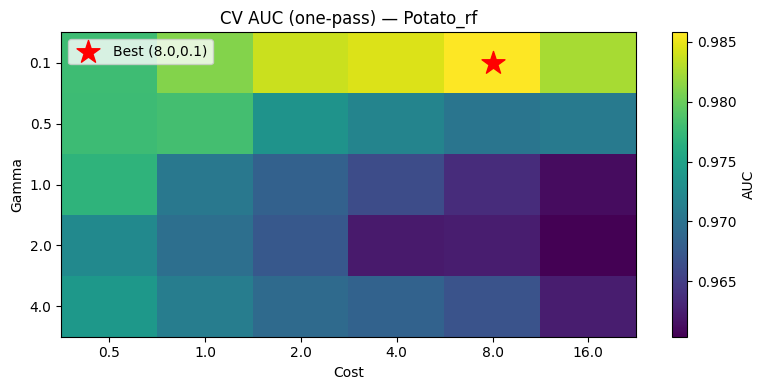

In [6]:
# Heatmap AUC
pivot = cv_df.pivot(index='gamma', columns='cost', values='AUC')
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(pivot.values, aspect='auto', cmap='viridis')
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)));   ax.set_yticklabels(pivot.index)
ax.set_xlabel('Cost'); ax.set_ylabel('Gamma')
ax.set_title(f'CV AUC (one-pass) — {CROP_LABEL}')
plt.colorbar(im, ax=ax, label='AUC')
ax.scatter([list(pivot.columns).index(best_cost)],
           [list(pivot.index).index(best_gamma)],
           marker='*', s=300, color='red', label=f'Best ({best_cost},{best_gamma})')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / f'cv_heatmap_{CROP_LABEL}.png', dpi=100)
plt.show()

## 4. Train final model on full dataset

In [7]:
print(f"Training final model: cost={best_cost}, gamma={best_gamma}")

# Scale on full dataset
scaler_final = StandardScaler()
X_scaled     = scaler_final.fit_transform(X)

# One-pass fit
svm_final = fit_svm_one_pass(X_scaled, y, best_cost, best_gamma)

# Training set performance (informative only)
y_pred_train = svm_final.predict(X_scaled)
cm = confusion_matrix(y, y_pred_train)
tn, fp, fn, tp = cm.ravel()
print(f"  Train sensitivity: {tp/(tp+fn):.3f}")
print(f"  Train specificity: {tn/(tn+fp):.3f}")
print("Final model trained (one-pass).")

Training final model: cost=8.0, gamma=0.1
  Train sensitivity: 0.961
  Train specificity: 0.969
Final model trained (one-pass).


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 5. Save model

In [8]:
model_bundle = {
    'model'      : svm_final,
    'scaler'     : scaler_final,
    'bio_cols'   : BIO_COLS,
    'best_cost'  : best_cost,
    'best_gamma' : best_gamma,
    'crop_label' : CROP_LABEL,
    'n_class1'   : int(n_pos),
    'n_class0'   : int(n_neg),
    'method'     : 'one_pass',
}
model_path = OUT_DIR / f'svm_model_{CROP_LABEL}.joblib'
joblib.dump(model_bundle, model_path)
print(f"Model saved: {model_path}")
print("Next step: 4.0)_SVM_predict_ERA5_1deg_one_pass.ipynb")

Model saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\3_SVM_train\3.0.d)_SVM_train_ERA5_MIRCA2000_no_threshold_one_pass\svm_train_outputs_mirca2000_no_threshold_one_pass\svm_model_Potato_rf.joblib
Next step: 4.0)_SVM_predict_ERA5_1deg_one_pass.ipynb
